# Hybrid RRNCO-PARCO — Inference & Visualization

This notebook loads a **trained checkpoint** and runs inference on HCVRP test datasets
with different decoding strategies (**greedy** / **sampling**), then visualises the resulting routes.

It mirrors the logic of `inference.py` in an interactive, notebook-friendly format.

**Prerequisites:**
- A trained `.ckpt` file (from `train.py` or Hydra training)
- Test data in `.npz` format (under `data/hcvrp_real/`)

**Sections:**
1. Import Required Libraries
2. Load Checkpoint and Model
3. Load Dataset
4. Run Inference (Greedy & Sampling)
5. Visualize Results (Routes, Cost Distributions, Per-Agent Analysis)

## 1. Import Required Libraries

Import necessary libraries: `torch`, `matplotlib`, custom modules (`HybridRLModule`, `HCVRPRealEnv`), and data utilities.

In [3]:
%load_ext autoreload
%autoreload 2

import glob
import os
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib import cm
from omegaconf import DictConfig, ListConfig
from omegaconf.base import ContainerMetadata
from omegaconf.nodes import ValueNode
from rl4co.data.utils import load_npz_to_tensordict
from tqdm.auto import tqdm

# Allow loading Hydra/OmegaConf configs from checkpoints (PyTorch 2.6+)
torch.serialization.add_safe_globals(
    [DictConfig, ListConfig, ContainerMetadata, ValueNode]
)

from hybrid.envs import HCVRPRealEnv
from hybrid.models import HybridRLModule
from parco.tasks.eval import get_dataloader

warnings.filterwarnings("ignore", category=FutureWarning)
torch.set_float32_matmul_precision("medium")

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Using device: cuda:0


## 2. Load Checkpoint and Model

Load the `HybridRLModule` from a Lightning checkpoint and extract the policy.

> **Update `CHECKPOINT_PATH`** below to point to your trained `.ckpt` file.

In [4]:
# ── Configuration ────────────────────────────────────────────────────
# Update these paths to match your setup
CHECKPOINT_DIR = "../logs/train/runs/2026-03-31_23-36-31/checkpoints"
CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "last.ckpt")  # or e.g. "epoch_005.ckpt"

# Decoding parameters
DECODE_TYPE = "greedy"       # "greedy" or "sampling"
SAMPLE_SIZE = 100            # Only used when DECODE_TYPE == "sampling"
BATCH_SIZE = 1               # Use 1 for sampling; can increase for greedy

# Number of instances to visualise in detail
NUM_VIS = 3

print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Exists:     {os.path.exists(CHECKPOINT_PATH)}")

Checkpoint: ../logs/train/runs/2026-03-31_23-36-31/checkpoints/last.ckpt
Exists:     True


In [5]:
def load_policy(checkpoint_path: str, device: torch.device):
    """Load the HybridRLModule from a checkpoint and return the policy on device."""
    assert os.path.exists(checkpoint_path), f"Checkpoint not found: {checkpoint_path}"
    print(f"Loading checkpoint: {checkpoint_path}")

    try:
        model = HybridRLModule.load_from_checkpoint(
            checkpoint_path, map_location="cpu", strict=False
        )
    except Exception:
        print("  Safe-globals load failed; retrying with weights_only=False")
        model = HybridRLModule.load_from_checkpoint(
            checkpoint_path, map_location="cpu", strict=False, weights_only=False
        )

    policy = model.policy.to(device).eval()
    total_params = sum(p.numel() for p in policy.parameters())
    print(f"  Model loaded — {total_params:,} parameters")
    return policy


policy = load_policy(CHECKPOINT_PATH, device)
env = HCVRPRealEnv()
print("Environment: HCVRPRealEnv (ready)")

Loading checkpoint: ../logs/train/runs/2026-03-31_23-36-31/checkpoints/last.ckpt
  Safe-globals load failed; retrying with weights_only=False
  Safe-globals load failed; retrying with weights_only=False


/home/wisdom1/Documents/NhutTien/rrnco_parco/.venv/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'env' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['env'])`.
/home/wisdom1/Documents/NhutTien/rrnco_parco/.venv/lib/python3.11/site-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'policy' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['policy'])`.


  Model loaded — 2,904,360 parameters
Environment: HCVRPRealEnv (ready)
Environment: HCVRPRealEnv (ready)


## 3. Load Dataset

Discover and load `.npz` test datasets from the `data/hcvrp_real/` directory.

In [6]:
# ── Auto-discover datasets ───────────────────────────────────────────
DATA_DIR = "../data/hcvrp_real"

DATASET_PATHS = sorted([
    os.path.join(DATA_DIR, f)
    for f in os.listdir(DATA_DIR)
    if f.endswith(".npz") and "sol" not in f
])

print(f"Found {len(DATASET_PATHS)} dataset(s):")
for p in DATASET_PATHS:
    td_tmp = load_npz_to_tensordict(p)
    print(f"  • {os.path.basename(p):50s}  ({len(td_tmp)} instances)")

Found 4 dataset(s):
  • hcvrp_real_n100_m7_s1280_in_dist_seed42.npz         (1248 instances)
  • hcvrp_real_n100_m7_s1280_out_dist_seed42.npz        (1280 instances)
  • test_real_n100_m7.npz                               (1248 instances)
  • val_real_n100_m7.npz                                (1248 instances)
  • hcvrp_real_n100_m7_s1280_out_dist_seed42.npz        (1280 instances)
  • test_real_n100_m7.npz                               (1248 instances)
  • val_real_n100_m7.npz                                (1248 instances)


## 4. Run Inference

Evaluate the model across all datasets, collecting per-instance costs and timing.
This follows the same logic as `inference.py`'s `run_inference()` function.

In [7]:
def run_inference(
    policy, env, data_paths, device,
    decode_type="greedy", sample_size=None, batch_size=1,
):
    """Run inference on a list of datasets and return results dict."""
    all_results = {}

    for dataset_path in data_paths:
        name = os.path.basename(dataset_path)
        print(f"\n{'='*60}")
        print(f"Dataset: {name}")
        print(f"{'='*60}")

        costs, inference_times, eval_steps = [], [], []
        td_test = load_npz_to_tensordict(dataset_path)
        dataloader = get_dataloader(td_test, batch_size=batch_size)

        print(f"  Instances: {len(td_test)} | Decode: {decode_type}"
              + (f" | Samples: {sample_size}" if decode_type == "sampling" else ""))

        ctx = (
            torch.autocast("cuda")
            if device.type == "cuda"
            else torch.inference_mode()
        )

        with ctx:
            with torch.inference_mode():
                for batch in tqdm(dataloader, desc="  Evaluating"):
                    td_reset = env.reset(batch).to(device)

                    t0 = time.time()
                    out = policy(
                        td_reset, env,
                        decode_type=decode_type,
                        num_samples=sample_size,
                        return_actions=False,
                    )
                    dt = time.time() - t0

                    if decode_type == "greedy":
                        costs.extend((-out["reward"]).tolist())
                    else:
                        costs.extend(
                            (-out["reward"]
                             .reshape(-1, sample_size)
                             .max(dim=-1)[0]).tolist()
                        )

                    inference_times.append(dt)
                    if "steps" in out:
                        eval_steps.append(out["steps"])

        avg_cost = sum(costs) / len(costs)
        total_time = sum(inference_times)
        avg_time = total_time / len(inference_times)

        print(f"\n  Results:")
        print(f"    Average cost:           {avg_cost:.4f}")
        print(f"    Per-batch infer time:   {avg_time:.4f}s")
        print(f"    Total inference time:   {total_time:.4f}s")
        if eval_steps:
            print(f"    Average eval steps:     {sum(eval_steps)/len(eval_steps):.2f}")

        all_results[name] = {
            "avg_cost": avg_cost,
            "total_time": total_time,
            "avg_time_per_batch": avg_time,
            "costs": costs,
        }

    return all_results


# ── Run ──────────────────────────────────────────────────────────────
results = run_inference(
    policy, env, DATASET_PATHS, device,
    decode_type=DECODE_TYPE,
    sample_size=SAMPLE_SIZE if DECODE_TYPE == "sampling" else None,
    batch_size=BATCH_SIZE,
)


Dataset: hcvrp_real_n100_m7_s1280_in_dist_seed42.npz
  Instances: 1248 | Decode: greedy
  Instances: 1248 | Decode: greedy


  Evaluating: 100%|██████████| 1248/1248 [03:31<00:00,  5.91it/s]




  Results:
    Average cost:           6.2054
    Per-batch infer time:   0.1671s
    Total inference time:   208.5944s
    Average eval steps:     48.10

Dataset: hcvrp_real_n100_m7_s1280_out_dist_seed42.npz
  Instances: 1280 | Decode: greedy


  Evaluating: 100%|██████████| 1280/1280 [03:34<00:00,  5.97it/s]




  Results:
    Average cost:           6.2137
    Per-batch infer time:   0.1653s
    Total inference time:   211.5736s
    Average eval steps:     48.08

Dataset: test_real_n100_m7.npz
  Instances: 1248 | Decode: greedy


  Evaluating: 100%|██████████| 1248/1248 [03:27<00:00,  6.02it/s]




  Results:
    Average cost:           6.2023
    Per-batch infer time:   0.1641s
    Total inference time:   204.8362s
    Average eval steps:     48.05

Dataset: val_real_n100_m7.npz
  Instances: 1248 | Decode: greedy


  Evaluating: 100%|██████████| 1248/1248 [03:27<00:00,  6.02it/s]


  Results:
    Average cost:           6.2051
    Per-batch infer time:   0.1641s
    Total inference time:   204.8477s
    Average eval steps:     48.16


In [8]:
# ── Summary Table ────────────────────────────────────────────────────
print(f"\n{'='*68}")
print(f"{'Dataset':<45} {'Avg Cost':>10} {'Time (s)':>10}")
print(f"{'-'*45} {'-'*10} {'-'*10}")
for name, res in results.items():
    print(f"{name:<45} {res['avg_cost']:>10.4f} {res['total_time']:>10.2f}")
print(f"{'='*68}")


Dataset                                         Avg Cost   Time (s)
--------------------------------------------- ---------- ----------
hcvrp_real_n100_m7_s1280_in_dist_seed42.npz       6.2054     208.59
hcvrp_real_n100_m7_s1280_out_dist_seed42.npz      6.2137     211.57
test_real_n100_m7.npz                             6.2023     204.84
val_real_n100_m7.npz                              6.2051     204.85


## 5. Visualize Results

Visualize inference results: cost distributions, individual route plots, and per-agent analysis.

### 5.1 Cost Distribution

Histogram of per-instance costs for each dataset.

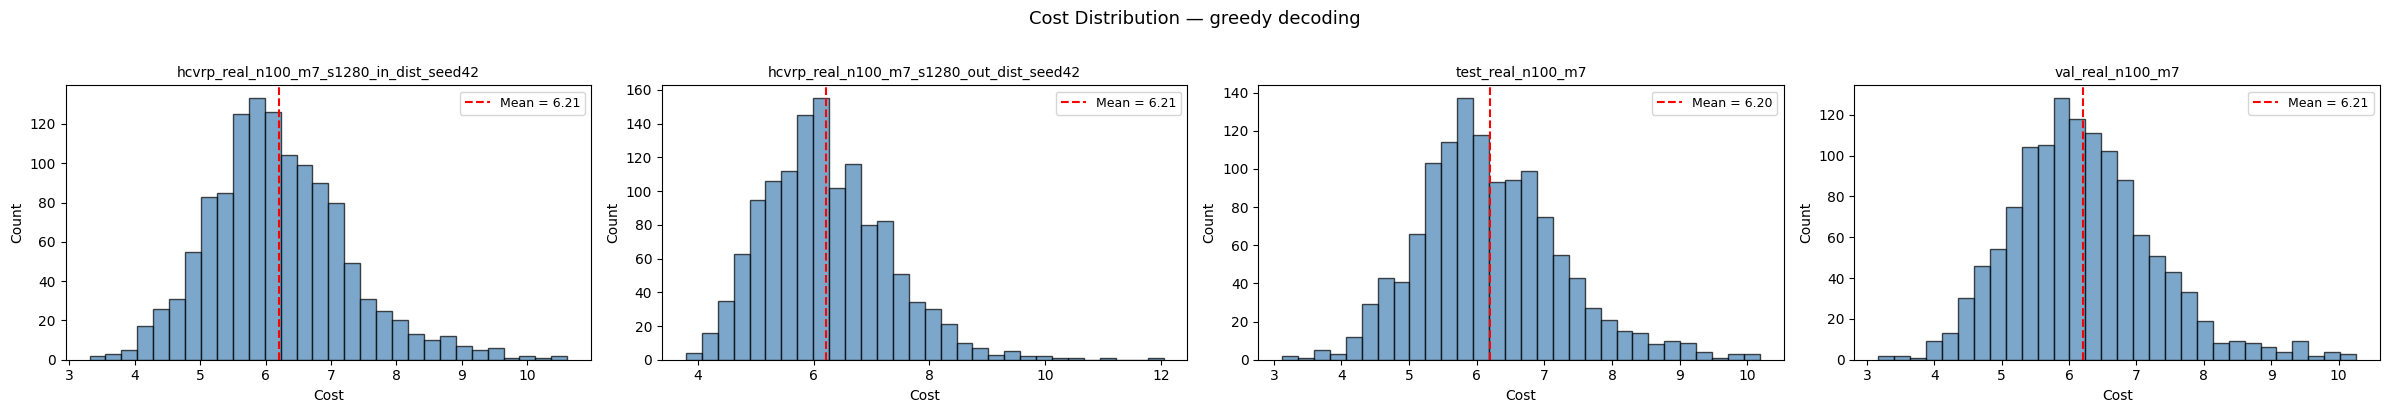

In [9]:
n_datasets = len(results)
fig, axes = plt.subplots(1, n_datasets, figsize=(6 * n_datasets, 4), squeeze=False)

for ax, (name, res) in zip(axes[0], results.items()):
    ax.hist(res["costs"], bins=30, edgecolor="black", alpha=0.7, color="steelblue")
    ax.axvline(
        res["avg_cost"], color="red", ls="--", lw=1.5,
        label=f"Mean = {res['avg_cost']:.2f}",
    )
    ax.set_title(name.replace(".npz", ""), fontsize=10)
    ax.set_xlabel("Cost")
    ax.set_ylabel("Count")
    ax.legend(fontsize=9)

plt.suptitle(f"Cost Distribution — {DECODE_TYPE} decoding", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### 5.2 Route Visualisation (Greedy)

Load a few instances from the first dataset and visualise the greedy routes.
Each agent's route is drawn in a different colour; dashed lines indicate depot transitions.

Visualising from: hcvrp_real_n100_m7_s1280_in_dist_seed42.npz


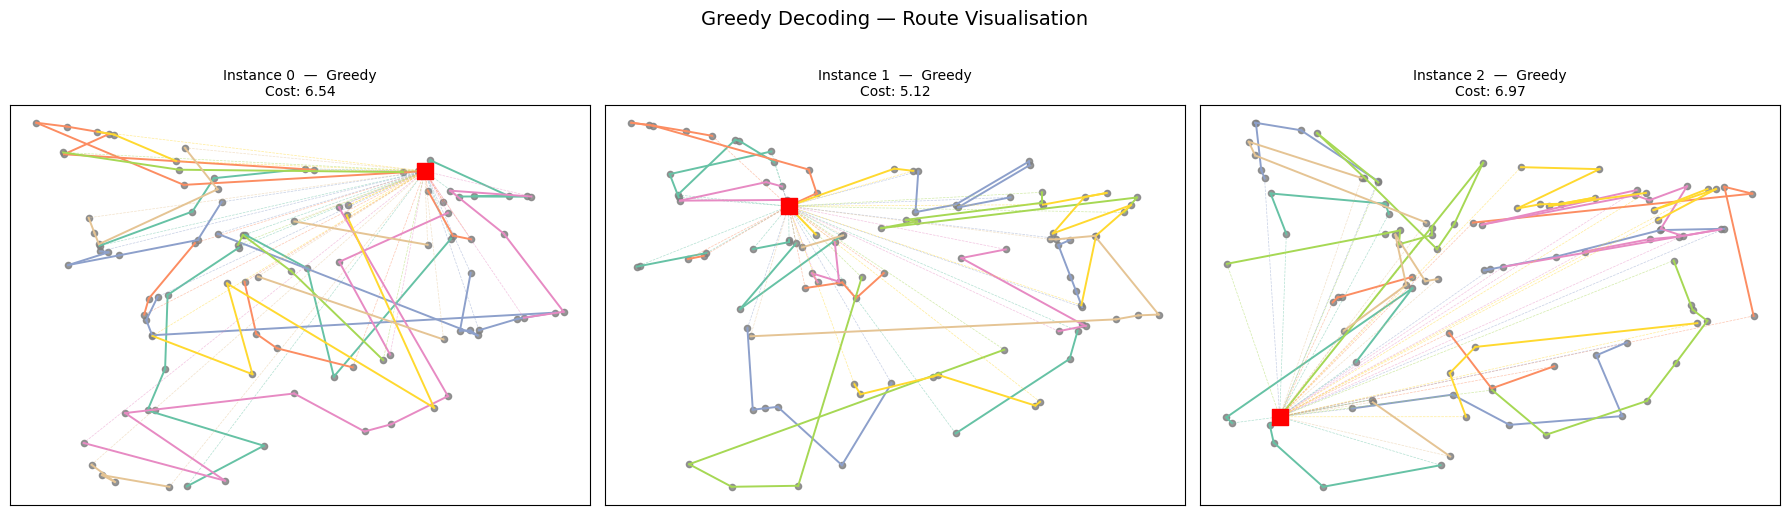


Average cost (greedy, 3 instances): 6.2084


In [11]:
def render_on_ax(ax, td, actions, title=None):
    """Render an HCVRP multi-agent solution on a matplotlib Axes."""
    td = td.detach().cpu()
    actions = actions.detach().cpu()
    if td.batch_size != torch.Size([]):
        td = td[0]
        actions = actions[0]

    num_agents = td["current_node"].size(-1)

    # Depot
    ax.scatter(
        td["locs"][0, 0], td["locs"][0, 1],
        marker="s", color="red", s=120, zorder=5, label="Depot",
    )
    # Customers
    ax.scatter(
        td["locs"][num_agents:, 0], td["locs"][num_agents:, 1],
        marker="o", color="tab:gray", s=20, alpha=0.8,
    )

    # Routes per agent
    depot_first = torch.arange(num_agents).unsqueeze(0).expand(actions.size(0), -1)
    actions_full = torch.cat([depot_first, actions, depot_first], dim=-1)

    for agent_idx in range(num_agents):
        route = actions_full[agent_idx]
        for j in range(route.size(0) - 1):
            src = td["locs"][route[j]]
            dst = td["locs"][route[j + 1]]
            is_depot = (route[j] == agent_idx) or (route[j + 1] == agent_idx)
            ax.plot(
                [src[0], dst[0]], [src[1], dst[1]],
                color=cm.Set2(agent_idx),
                lw=0.5 if is_depot else 1.4,
                ls="--" if is_depot else "-",
                alpha=0.5 if is_depot else 1.0,
            )

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=10)


# ── Pick dataset & run greedy ────────────────────────────────────────
VIS_DATASET = DATASET_PATHS[0]  # change index to pick a different dataset
print(f"Visualising from: {os.path.basename(VIS_DATASET)}")

td_vis = load_npz_to_tensordict(VIS_DATASET)[:NUM_VIS]
td_vis_reset = env.reset(td_vis.clone()).to(device)

with torch.inference_mode():
    out_greedy = policy(
        td_vis_reset.clone(), env,
        decode_type="greedy", return_actions=True,
    )

fig, axes = plt.subplots(1, NUM_VIS, figsize=(6 * NUM_VIS, 5))
if NUM_VIS == 1:
    axes = [axes]
for i in range(NUM_VIS):
    cost_i = -out_greedy["reward"][i].item()
    render_on_ax(
        axes[i], td_vis_reset[i], out_greedy["actions"][i],
        title=f"Instance {i}  —  Greedy\nCost: {cost_i:.2f}",
    )

plt.suptitle("Greedy Decoding — Route Visualisation", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print(f"\nAverage cost (greedy, {NUM_VIS} instances): "
      f"{-out_greedy['reward'].mean().item():.4f}")

### 5.3 Route Visualisation (Sampling — Best of N)

Sample multiple solutions per instance and keep the best one.

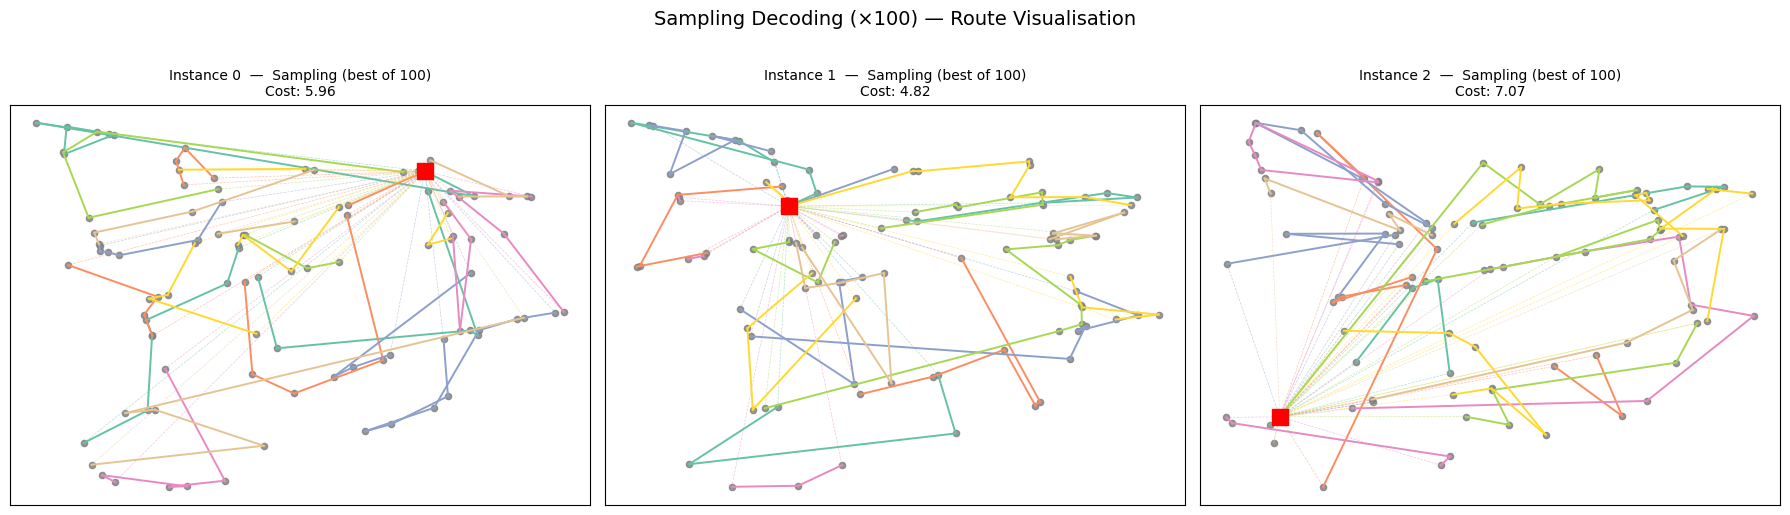


Average cost (sampling best-of-100, 3 instances): 5.9472


In [12]:
NUM_SAMPLES = 100  # number of samples per instance

with torch.inference_mode():
    out_sampling = policy(
        td_vis_reset.clone(), env,
        decode_type="sampling",
        num_samples=NUM_SAMPLES,
        return_actions=True,
    )

# Reshape: [batch * samples] → [batch, samples]
rewards_s = out_sampling["reward"].reshape(NUM_VIS, NUM_SAMPLES)
best_idx = rewards_s.argmax(dim=-1)

actions_all = out_sampling["actions"].reshape(
    NUM_VIS, NUM_SAMPLES, *out_sampling["actions"].shape[1:]
)
best_rewards = rewards_s.gather(1, best_idx.unsqueeze(-1)).squeeze(-1)

fig, axes = plt.subplots(1, NUM_VIS, figsize=(6 * NUM_VIS, 5))
if NUM_VIS == 1:
    axes = [axes]
for i in range(NUM_VIS):
    best_action = actions_all[i, best_idx[i]]
    cost_i = -best_rewards[i].item()
    render_on_ax(
        axes[i], td_vis_reset[i], best_action,
        title=f"Instance {i}  —  Sampling (best of {NUM_SAMPLES})\nCost: {cost_i:.2f}",
    )

plt.suptitle(f"Sampling Decoding (×{NUM_SAMPLES}) — Route Visualisation", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print(f"\nAverage cost (sampling best-of-{NUM_SAMPLES}, {NUM_VIS} instances): "
      f"{-best_rewards.mean().item():.4f}")

### 5.4 Side-by-Side: Greedy vs Sampling

Compare greedy and sampling (best-of-N) routes for each visualised instance.

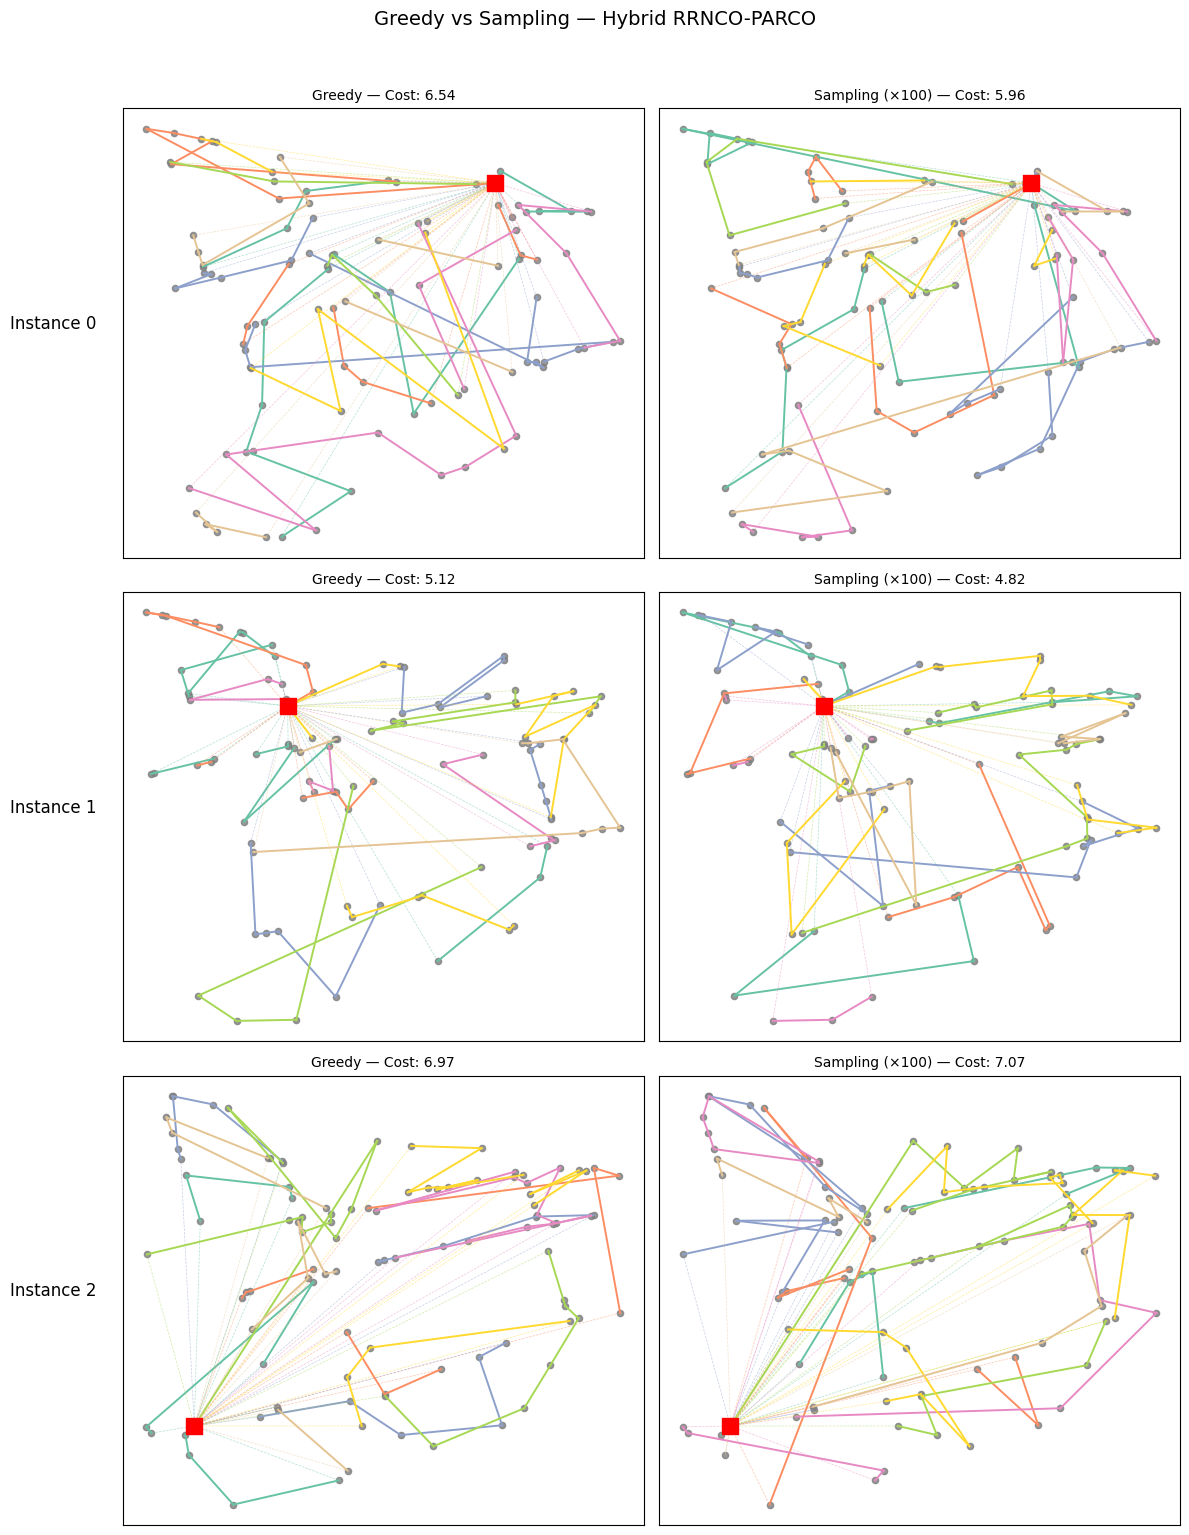

In [13]:
fig, axes = plt.subplots(NUM_VIS, 2, figsize=(12, 5 * NUM_VIS))
if NUM_VIS == 1:
    axes = axes.reshape(1, 2)

for i in range(NUM_VIS):
    # Greedy
    cost_g = -out_greedy["reward"][i].item()
    render_on_ax(
        axes[i, 0], td_vis_reset[i], out_greedy["actions"][i],
        title=f"Greedy — Cost: {cost_g:.2f}",
    )
    # Sampling
    best_action = actions_all[i, best_idx[i]]
    cost_s = -best_rewards[i].item()
    render_on_ax(
        axes[i, 1], td_vis_reset[i], best_action,
        title=f"Sampling (×{NUM_SAMPLES}) — Cost: {cost_s:.2f}",
    )
    axes[i, 0].set_ylabel(f"Instance {i}", fontsize=12, rotation=0, labelpad=50)

plt.suptitle(
    "Greedy vs Sampling — Hybrid RRNCO-PARCO",
    fontsize=14, y=1.02,
)
plt.tight_layout()
plt.show()

### 5.5 Per-Agent Route Analysis

Break down route lengths and customer counts per agent for the greedy solution.


── Instance 0 ──
  Agent   Customers    Distance
      0          27       4.632
      1          18       3.313
      2          18       4.062
      3          27       4.597
      4          10       2.698
      5          10       3.029
      6          14       4.040

── Instance 1 ──
  Agent   Customers    Distance
      0          21       3.778
      1          15       1.803
      2          19       2.774
      3          16       2.240
      4          18       3.573
      5          23       2.468
      6          14       2.093

── Instance 2 ──
  Agent   Customers    Distance
      0          14       3.089
      1          18       3.580
      2          17       3.390
      3          12       3.289
      4          24       4.308
      5          24       3.379
      6          11       2.747


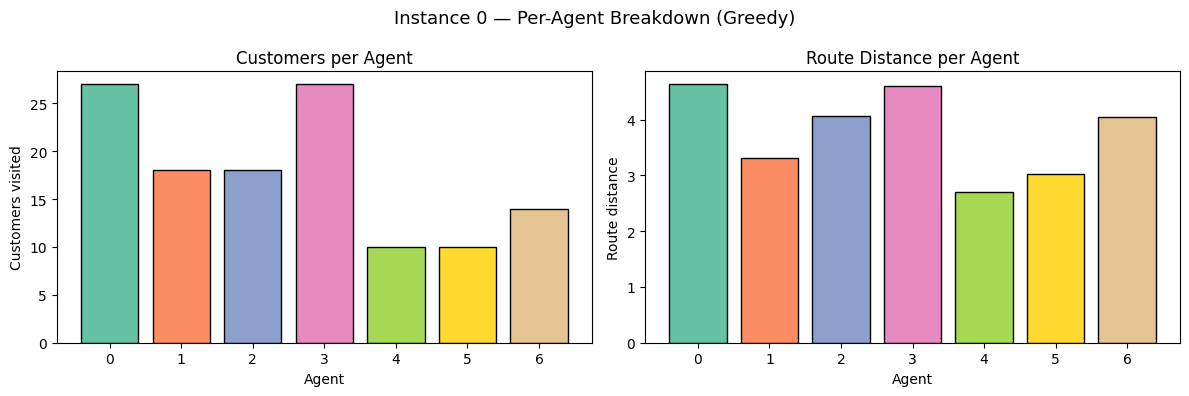

In [14]:
def analyse_routes(td, actions):
    """Return per-agent statistics for a single instance."""
    td = td.detach().cpu()
    actions = actions.detach().cpu()
    if td.batch_size != torch.Size([]):
        td = td[0]
        actions = actions[0]

    num_agents = td["current_node"].size(-1)
    locs = td["locs"]
    stats = []

    for a in range(num_agents):
        route = actions[a]
        customers = route[route >= num_agents]
        n_cust = len(customers)

        # Compute route length: depot → customers → depot
        full_route = torch.cat([
            torch.tensor([a]),
            route[route != a],
            torch.tensor([a]),
        ])
        dist = 0.0
        for j in range(len(full_route) - 1):
            dist += (locs[full_route[j]] - locs[full_route[j + 1]]).norm().item()

        stats.append({"agent": a, "customers": n_cust, "distance": dist})
    return stats


# ── Print per-agent stats ────────────────────────────────────────────
for i in range(NUM_VIS):
    stats = analyse_routes(td_vis_reset[i], out_greedy["actions"][i])
    print(f"\n── Instance {i} ──")
    print(f"  {'Agent':>5}  {'Customers':>10}  {'Distance':>10}")
    for s in stats:
        print(f"  {s['agent']:>5}  {s['customers']:>10}  {s['distance']:>10.3f}")

# ── Bar charts for Instance 0 ────────────────────────────────────────
stats_0 = analyse_routes(td_vis_reset[0], out_greedy["actions"][0])
agents = [s["agent"] for s in stats_0]
cust_counts = [s["customers"] for s in stats_0]
distances = [s["distance"] for s in stats_0]
colors = [cm.Set2(a) for a in agents]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.bar(agents, cust_counts, color=colors, edgecolor="black")
ax1.set_xlabel("Agent")
ax1.set_ylabel("Customers visited")
ax1.set_title("Customers per Agent")

ax2.bar(agents, distances, color=colors, edgecolor="black")
ax2.set_xlabel("Agent")
ax2.set_ylabel("Route distance")
ax2.set_title("Route Distance per Agent")

plt.suptitle("Instance 0 — Per-Agent Breakdown (Greedy)", fontsize=13)
plt.tight_layout()
plt.show()

### 5.6 Cross-Dataset Cost Comparison

If multiple datasets were evaluated, compare average costs and inference times.

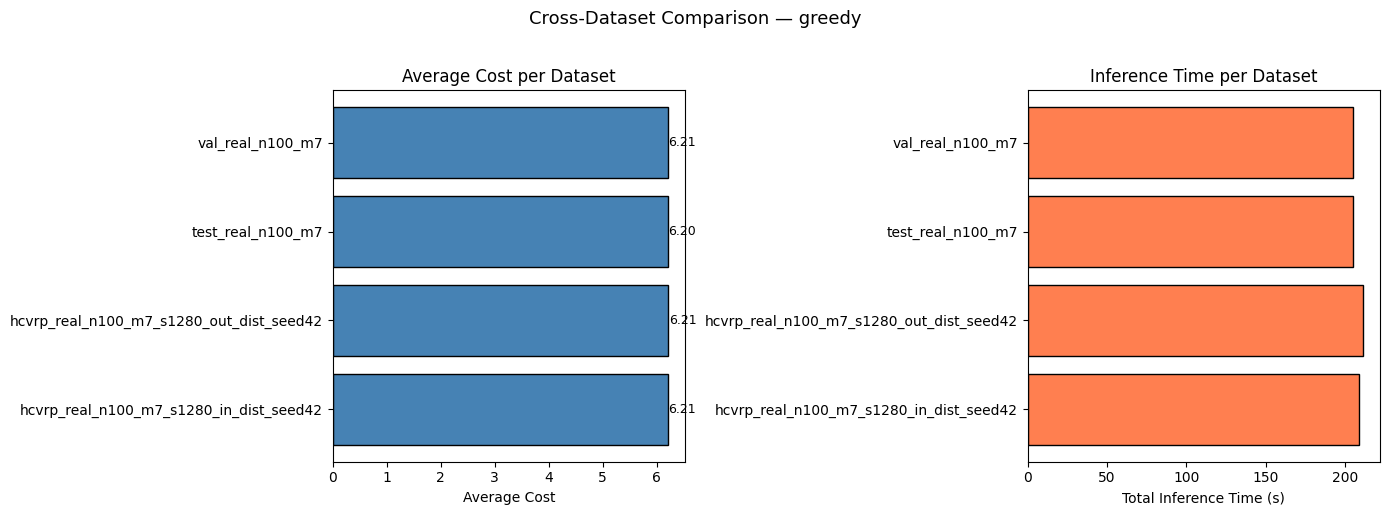

In [15]:
if len(results) > 1:
    names = [n.replace(".npz", "") for n in results.keys()]
    avg_costs = [r["avg_cost"] for r in results.values()]
    times = [r["total_time"] for r in results.values()]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    bars = ax1.barh(names, avg_costs, color="steelblue", edgecolor="black")
    ax1.set_xlabel("Average Cost")
    ax1.set_title("Average Cost per Dataset")
    for bar, val in zip(bars, avg_costs):
        ax1.text(
            bar.get_width() + 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{val:.2f}", va="center", fontsize=9,
        )

    ax2.barh(names, times, color="coral", edgecolor="black")
    ax2.set_xlabel("Total Inference Time (s)")
    ax2.set_title("Inference Time per Dataset")

    plt.suptitle(f"Cross-Dataset Comparison — {DECODE_TYPE}", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("Only one dataset evaluated — skipping cross-dataset comparison.")

## Notes

- **Greedy** decoding is deterministic and fast — good for benchmarks.
- **Sampling** (best-of-N) usually yields better costs at the expense of N× more compute.
- To evaluate a different checkpoint, update `CHECKPOINT_PATH` in cell 5 and re-run from cell 6.
- For command-line inference, use:

```bash
python inference.py --checkpoint <path> --datasets <npz_files> --decode_type greedy
python inference.py --checkpoint <path> --decode_type sampling --sample_size 100
```